# Cross-species comparison of skeletal muscle development using SAMap

## Objective


This notebook explores the conservation and divergence of skeletal muscle developmental programs across vertebrate species using SAMap, a method that combines single-cell transcriptomic similarity with sequence-based gene homology.

The workflow was initially designed to compare three species:

Mus musculus (mouse)
Danio rerio (zebrafish)
Homo sapiens (human)

All three datasets were prepared for SAMap, including gene-name harmonization and pairwise sequence-based gene maps. 
However, for the current FAIR-oriented analysis, the final SAMap integration was restricted to mouse and zebrafish. The rationale for this choice is described below.

## Reading and execution notes


Review the paths below before running. The human dataset is prepared and inspected, but the final integration uses mouse and zebrafish only. UMAPs of the source datasets use embeddings already stored in their H5AD files. New mouse UMAPs, where applicable, follow preprocessing and clustering.

## Dataset selection and FAIR considerations

An important objective of this work is not only to obtain biologically meaningful cross-species comparisons, but also to build a workflow that can be reproduced and reused within a FAIR framework.

The mouse and zebrafish datasets used here are already curated and distributed through CZ CELLxGENE, with standardized metadata, persistent dataset references, and explicit provenance. This makes them particularly suitable candidates for subsequent integration into a scFAIR-oriented workflow.

The situation is different for the human skeletal muscle dataset. The dataset originally referenced in the literature is no longer accessible through the published download links. After contacting the corresponding authors, they very kindly provided a version containing the original raw count matrices. The dataset appears to be of very good quality and could technically be included in the SAMap analysis.

However, because this version was obtained through direct personal communication and is not currently available from a public, persistent and independently accessible repository, I decided not to include it in the main FAIR-oriented SAMap analysis.

This is therefore a decision based on data accessibility and reproducibility rather than on data quality.

Importantly, the human dataset has nevertheless been fully prepared for SAMap, and the human–mouse and human–zebrafish gene maps have already been generated. Reintroducing the human dataset into a future three-species analysis would therefore require only minimal additional work if this is preferred.

## Environment and paths

The reannotated source notebook records `sc-samap==3.0.1`; install or update dependencies **before** starting the kernel, rather than midway through an analysis. The reanalysis uses the Scanpy >= 1.10 PCA syntax from the original code and the igraph Leiden backend.

Optional environment setup (run separately, then restart the kernel):

```bash
conda activate SAMapv3
python -m pip install "sc-samap==3.0.1"
```

The reference-generation shell commands below are documentation for a separate terminal session. They are not Python cells and are not executed by Run All. Adapt the terminal `PROJECT_DIR` to match the Python configuration and run the shell snippets in the same activated terminal session. Gene maps are read from `PROJECT_DIR / "maps"`.

In [2]:
from samap import SAMAP
from samap.analysis import (get_mapping_scores, GenePairFinder,
                            sankey_plot, CellTypeTriangles, 
                            ParalogSubstitutions, FunctionalEnrichment,
                            convert_eggnog_to_homologs, GeneTriangles)
from samap.sam import SAM
import pandas as pd

import scanpy as sc
import anndata as ad
import numpy as np
from pathlib import Path
import scipy.sparse as sp
from samap.utils import save_samap, load_samap
import matplotlib.colors as mcolors

In [3]:
RAW_DIR = Path('/media/sabrina/hdd1/BioHack26')
PROJECT_DIR = Path('/home/sabrina/Documents/BioHack26/samap_3species')
PROCESSED_DIR = PROJECT_DIR / "data" / "processed_h5ad"
SAMAP_OUTPUT_DIR = PROJECT_DIR / "data" / "samap"
MAPS_DIR = PROJECT_DIR / "maps"

RAW_FILES = {
    "human": RAW_DIR / "221024LimbCellranger3annotated_filtered_adjusted_skm_lineage_raw_counts_20260817.h5ad",
    "mouse": RAW_DIR / "MusMusculus_atlas_musclecells.h5ad",
    "zebrafish": RAW_DIR / "Zebrafish_dev_atlas.h5ad",
}
HUMAN_READY_PATH = PROCESSED_DIR / "human_SKM_samap_ready.h5ad"
MOUSE_READY_PATH = PROCESSED_DIR / "mouse_SKM_samap_ready.h5ad"
ZEBRAFISH_READY_PATH = PROCESSED_DIR / "zebrafish_SKM_samap_ready.h5ad"
MOUSE_ANNOTATED_PATH = PROCESSED_DIR / "mouse_annot_SKM_samap_ready.h5ad"
SAMAP_H5AD_PATH = Path("samap_mm_dr_annot.h5ad")
SAMAP_OBJECT_PATH = SAMAP_OUTPUT_DIR / "SamapObject_mm_dr_annot"

# Default: reuse the saved manual annotations, clustering, and embeddings.
# Rebuilding requires the complete, verified cluster-to-cell-type mapping below.
REBUILD_MOUSE_ANNOTATION = True # False
MANUAL_ANNOTATIONS = {
    "0":"MyoProg_Pax3",
    "1":"MyoProg_Pax7_Col15",
    "2":"MyoProg_Pax3_Pax7",
    "3":"MyoB_Jam3",
    "4":"MyoProg_Pax7_Mki67",
    "5":"MyoC",
    "6":"MyoC_Myh3",
    "7":"MyoC_Myh8",
    "8":"MyoB_Cadm1_Myf5",
    "9":"MyoB_Mki67"
}  # {}# Fill only with verified labels for every leiden_re_0.4 cluster.

## Matrix diagnostic helpers

In [3]:
import numpy as np
import scipy.sparse as sp
import pandas as pd


def matrix_diagnostics(
    adata,
    matrix,
    label,
    n_sample=200_000,
    seed=123
):

    rng = np.random.default_rng(seed)

    # -----------------------------
    # Inspect values
    # -----------------------------

    if sp.issparse(matrix):

        values = matrix.data

        if values.size > n_sample:
            ix = rng.choice(
                values.size,
                size=n_sample,
                replace=False
            )

            values = values[ix]

    else:

        arr = np.asarray(matrix)

        n = min(
            n_sample,
            arr.size
        )

        ix = rng.integers(
            0,
            arr.size,
            size=n
        )

        values = arr.reshape(-1)[ix]

    values = np.asarray(
        values,
        dtype=float
    )

    values = values[
        np.isfinite(values)
    ]

    values = values[
        values != 0
    ]

    # -----------------------------
    # Evaluation
    # -----------------------------

    if len(values) == 0:

        integer_fraction = np.nan
        minimum = np.nan
        maximum = np.nan
        median = np.nan

    else:

        integer_fraction = np.mean(
            np.isclose(
                values,
                np.round(values),
                atol=1e-8
            )
        )

        minimum = np.min(values)
        maximum = np.max(values)
        median = np.median(values)

    likely_counts = (
        len(values) > 0
        and minimum >= 0
        and integer_fraction > 0.999
    )

    print("\n------------------------------------")
    print(label)
    print("------------------------------------")

    print("shape:", matrix.shape)
    print("dtype:", matrix.dtype)
    print("sparse:", sp.issparse(matrix))

    print(
        "fraction integer values:",
        round(integer_fraction, 6)
    )

    print("minimum non-zero:", minimum)
    print("median non-zero:", median)
    print("maximum:", maximum)

    print(
        ">>> seems value counts:",
        likely_counts
    )

    # -----------------------------
    # Sum per cells
    # on max 5000 cells
    # -----------------------------

    n_cells = min(
        5000,
        adata.n_obs
    )

    ix_cells = np.linspace(
        0,
        adata.n_obs - 1,
        n_cells,
        dtype=int
    )

    totals = np.asarray(
        matrix[ix_cells, :].sum(axis=1)
    ).ravel()

    print(
        "total/cell median:",
        np.median(totals)
    )

    print(
        "total/cell range:",
        np.min(totals),
        "-",
        np.max(totals)
    )

    # comparison with metadata
    for col in [
        "n_counts",
        "n.umi",
        "total_counts"
    ]:

        if col not in adata.obs:
            continue

        expected = pd.to_numeric(
            adata.obs.iloc[ix_cells][col],
            errors="coerce"
        ).to_numpy()

        valid = (
            np.isfinite(expected)
            & np.isfinite(totals)
        )

        if valid.sum() > 10:

            corr = np.corrcoef(
                totals[valid],
                expected[valid]
            )[0, 1]

            relative_error = np.median(
                np.abs(
                    totals[valid]
                    - expected[valid]
                )
                /
                (
                    np.abs(
                        expected[valid]
                    )
                    + 1
                )
            )

            print(
                f"corr with obs['{col}']:",
                round(corr, 5)
            )

            print(
                f"relative error to the median:",
                round(relative_error, 5)
            )

    return likely_counts

In [4]:
def inspect_adata_matrices(
    adata,
    name
):

    print("\n")
    print("=" * 70)
    print(name)
    print("=" * 70)

    results = {}

    results["X"] = matrix_diagnostics(
        adata,
        adata.X,
        f"{name} : X"
    )

    if adata.raw is not None:

        results["raw"] = matrix_diagnostics(
            adata,
            adata.raw.X,
            f"{name} : raw.X"
        )

    for layer in adata.layers.keys():

        results[
            f"layer:{layer}"
        ] = matrix_diagnostics(
            adata,
            adata.layers[layer],
            f"{name} : layers['{layer}']"
        )

    print("\nCandidates for original counts:")

    for source, is_counts in results.items():

        if is_counts:
            print("  ", source)

    return results

In [ ]:
hs = sc.read_h5ad(RAW_FILES["human"])
dr = sc.read_h5ad(RAW_FILES["zebrafish"])
mm = sc.read_h5ad(RAW_FILES["mouse"])

In [ ]:
files = RAW_FILES

In [ ]:
for species, f in files.items():
    adata = sc.read_h5ad(f)

    print("\n==============================")
    print(species)
    print("==============================")
    print(adata)
    
    print("\nFirst 20 var_names:")
    print(adata.var_names[:20].tolist())

    print("\nColumns in adata.var:")
    print(adata.var.columns.tolist())

    print("\nFirst rows of adata.var:")
    print(adata.var.head())

    print("\nKeys in adata.uns:")
    print(list(adata.uns.keys()))


human
AnnData object with n_obs × n_vars = 12376 × 36601
    obs: 'batch', 'percent_mito', 'n_counts', 'n_genes', 'doublet_scores', 'bh_pval', 'pre-annotation', 'region', 'tissue', 'adj_stage', 'adj_sample', 'leiden', 'S_score', 'G2M_score', 'phase', 'leiden_R', 'predicted_labels', 'over_clustering', 'majority_voting', 'conf_score', 'celltype', 'new_celltype', 'leiden_R_celltype', 'myogenesis_cluster', 'main_CT'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    uns: 'adj_stage_colors', 'batch_colors', 'celltype_colors', 'celltype_sizes', 'leiden', 'leiden_R_celltype_colors', 'leiden_R_colors', 'leiden_sizes', 'log1p', 'majority_voting_colors', 'markers_celltype', 'markers_new_celltype', 'neighbors', 'new_celltype_colors', 'new_celltype_sizes', 'paga', 'pca', 'phase_colors', 'pre-annotation_colors', 'rank_genes_groups', 'region_colors', 'tissue_colors', 'umap'
    obsm: 'X_diffmap', 'X_draw_graph_fa', 'X_pca', 'X_umap'
    layers: 'ambiguous', 'matrix', 'spliced', 'unspl

## Harmonization of gene identifiers across datasets

The three datasets do not initially use the same type of gene identifier.

The human dataset already uses gene symbols as feature names, whereas the mouse and zebrafish CELLxGENE datasets use Ensembl gene identifiers as var_names and provide gene symbols in the gene_short_name field.

For interpretability, SAMap feature names were converted to gene symbols while retaining the original Ensembl gene identifiers in adata.var.

A complication is that gene symbols are not always unique. Several independent Ensembl gene identifiers can share the same gene symbol, particularly in the mouse and zebrafish annotations.

To avoid collapsing these biologically distinct features, unique SAMap identifiers were generated as follows:

unique gene symbol: GeneSymbol
ambiguous gene symbol: GeneSymbol__EnsemblGeneID

For example:

Hspa14__ENSMUSG...

or

rimbp2__ENSDARG...

This strategy preserves readable gene symbols while maintaining an unambiguous one-to-one correspondence between the AnnData features, the reference FASTA sequences, and the SAMap homology graph.

In [ ]:
# HUMAN
hs.var["ensembl_gene_id"] = hs.var["Accession"].astype(str)
hs.var["gene_symbol"] = hs.var_names.astype(str)

# MOUSE
mm.var["ensembl_gene_id"] = mm.var_names.astype(str)
mm.var["gene_symbol"] = mm.var["gene_short_name"].astype(str)

# ZEBRAFISH
dr.var["ensembl_gene_id"] = dr.var_names.astype(str)
dr.var["gene_symbol"] = dr.var["gene_short_name"].astype(str)

In [ ]:
for species, adata in {
    "human": hs,
    "mouse": mm,
    "zebrafish": dr
}.items():

    symbols = adata.var["gene_symbol"]

    print("\n", species)
    print("Gene number :", len(symbols))
    print("Missing symbols :", symbols.isna().sum())
    print("Duplicated gene names :", symbols.duplicated().sum())

    duplicates = symbols[symbols.duplicated(keep=False)]
    print("\nExamples - duplicated genes:")
    print(duplicates.head(20))


 human
Gene number : 36601
Missing symbols : 0
Duplicated gene names : 0

Examples - duplicated genes:
Series([], Name: gene_symbol, dtype: str)

 mouse
Gene number : 45525
Missing symbols : 0
Duplicated gene names : 37

Examples - duplicated genes:
ENSMUSG00000107979        Zfp813-ps
ENSMUSG00000101373        Zfp813-ps
ENSMUSG00000103890          Gm28724
ENSMUSG00000101909          Gm28724
ENSMUSG00000109865           Hspa14
ENSMUSG00000051396           Hspa14
ENSMUSG00000092201    A530058N18Rik
ENSMUSG00000087694    A530058N18Rik
ENSMUSG00000103532           Gm4430
ENSMUSG00000103009           Gm4430
ENSMUSG00000102853           Gm7270
ENSMUSG00000103218           Gm7270
ENSMUSG00000103007          Gm20690
ENSMUSG00000093730          Gm20690
ENSMUSG00000104144          Gm18433
ENSMUSG00000104229          Gm18433
ENSMUSG00000105595          Gm23011
ENSMUSG00000077336          Gm23011
ENSMUSG00000088675            Rprl1
ENSMUSG00000106222            Rprl1
Name: gene_symbol, dtype: str

In [ ]:
hs.var["ensembl_gene_id"] = hs.var["Accession"].astype(str)
hs.var["gene_symbol"] = hs.var_names.astype(str)
hs.var["samap_gene"] = hs.var["gene_symbol"]

hs.var_names = hs.var["samap_gene"]

In [5]:
def make_samap_gene_names(adata, symbol_col):
    # var_names are Ensembl Gene IDs
    gene_id = adata.var_names.astype(str)
    symbol = adata.var[symbol_col].astype(str)

    adata.var["ensembl_gene_id"] = gene_id
    adata.var["gene_symbol"] = symbol

    # group of duplicated genes
    duplicated = symbol.duplicated(keep=False)

    samap_gene = symbol.copy()

    # Adding Ensembl ID to ambiguous symbols
    samap_gene.loc[duplicated] = (
        symbol.loc[duplicated]
        + "__"
        + gene_id[duplicated]
    )

    adata.var["samap_gene"] = samap_gene
    adata.var_names = samap_gene

    print("Gene number :", adata.n_vars)
    print("Gene names are unique:", adata.var_names.is_unique)
    print("Number of ambiguous symbols:", duplicated.sum())

In [ ]:
make_samap_gene_names(
    mm,
    symbol_col="gene_short_name"
)

make_samap_gene_names(
    dr,
    symbol_col="gene_short_name"
)

Gene number : 45525
Gene names are unique: True
Number of ambiguous symbols: 74
Gene number : 32031
Gene names are unique: True
Number of ambiguous symbols: 1262


In [ ]:
mm.var.loc[
    mm.var["gene_symbol"].duplicated(keep=False),
    ["ensembl_gene_id", "gene_symbol", "samap_gene"]
].head(20)

,ensembl_gene_id,gene_symbol,samap_gene
gene_short_name,,,
Zfp813-ps__ENSMUSG00000107979,ENSMUSG00000107979,Zfp813-ps,Zfp813-ps__ENSMUSG00000107979
Zfp813-ps__ENSMUSG00000101373,ENSMUSG00000101373,Zfp813-ps,Zfp813-ps__ENSMUSG00000101373
Gm28724__ENSMUSG00000103890,ENSMUSG00000103890,Gm28724,Gm28724__ENSMUSG00000103890
Gm28724__ENSMUSG00000101909,ENSMUSG00000101909,Gm28724,Gm28724__ENSMUSG00000101909
Hspa14__ENSMUSG00000109865,ENSMUSG00000109865,Hspa14,Hspa14__ENSMUSG00000109865
Hspa14__ENSMUSG00000051396,ENSMUSG00000051396,Hspa14,Hspa14__ENSMUSG00000051396
A530058N18Rik__ENSMUSG00000092201,ENSMUSG00000092201,A530058N18Rik,A530058N18Rik__ENSMUSG00000092201
A530058N18Rik__ENSMUSG00000087694,ENSMUSG00000087694,A530058N18Rik,A530058N18Rik__ENSMUSG00000087694
Gm4430__ENSMUSG00000103532,ENSMUSG00000103532,Gm4430,Gm4430__ENSMUSG00000103532


## Construction of cross-species gene maps

SAMap requires a sequence-based homology graph in addition to the single-cell expression matrices.

Species-specific transcriptome references were therefore prepared for human, mouse and zebrafish. The FASTA identifiers were modified to exactly match the SAMap gene identifiers used in the corresponding AnnData objects.

For genes represented by multiple transcripts, a representative transcript was selected at the gene level. Ambiguous gene symbols retain the Ensembl gene identifier suffix described above.

Pairwise nucleotide homology searches were then performed for:

human ↔ mouse
human ↔ zebrafish
mouse ↔ zebrafish

Thus, although the current SAMap analysis contains only mouse and zebrafish, the sequence-based infrastructure required for a future three-species analysis is already available.

In [ ]:
import scanpy as sc

paths = RAW_FILES

for species, path in paths.items():
    adata = sc.read_h5ad(path, backed="r")

    print("\n====================")
    print(species)
    print("====================")
    print("shape:", adata.shape)
    print("schema_version:", adata.uns.get("schema_version"))
    print("organism:", adata.uns.get("organism"))
    print("title:", adata.uns.get("title"))
    print("citation:", adata.uns.get("citation"))

    adata.file.close()


human
shape: (12376, 36601)
schema_version: None
organism: None
title: None
citation: None

mouse
shape: (305003, 45525)
schema_version: 7.1.0
organism: Mus musculus
title: Major cell cluster: Muscle cells
citation: Publication: https://doi.org/10.1038/s41586-024-07069-w Dataset Version: https://datasets.cellxgene.cziscience.com/d33cc838-a0e3-40f7-ae99-0384b13db313.h5ad curated and distributed by CZ CELLxGENE Discover in Collection: https://cellxgene.cziscience.com/collections/45d5d2c3-bc28-4814-aed6-0bb6f0e11c82

zebrafish
shape: (1220178, 32031)
schema_version: 7.1.0
organism: Danio rerio
title: Developmental Zebrafish Atlas
citation: Publication: https://doi.org/10.1101/2025.04.03.646654 Dataset Version: https://datasets.cellxgene.cziscience.com/e3ae71af-1cd6-451b-8735-3d06e12d7360.h5ad curated and distributed by CZ CELLxGENE Discover in Collection: https://cellxgene.cziscience.com/collections/4ea9a90e-1dad-4c67-b1e3-8488ab7dc269


```bash
conda activate SAMapv3
PROJECT_DIR="/home/sabrina/Documents/BioHack26/samap_3species"
mkdir -p "$PROJECT_DIR/refs/raw" "$PROJECT_DIR/refs/samap" "$PROJECT_DIR/refs/mappings" "$PROJECT_DIR/scripts"
cd "$PROJECT_DIR"
git clone https://github.com/atarashansky/SAMap.git SAMap_git
chmod +x SAMap_git/map_genes.sh
# Provide the existing transcriptome download and FASTA-header scripts in scripts/.
# Download transcriptomes.
./scripts/01_download_transcriptomes.sh
# Match FASTA headers to var_names in the H5AD objects.
python scripts/02_build_samap_fastas.py
```

```bash
cd "$PROJECT_DIR"

THREADS=24
SAMAP_SCRIPT="./SAMap_git/map_genes.sh"
```

### Human ↔ mouse

```bash
$SAMAP_SCRIPT \
  --tr1 refs/samap/human.GRCh38.Ensembl93.samap.fa \
  --t1 nucl \
  --n1 hs \
  --tr2 refs/samap/mouse.GRCm38.GENCODEvM12.samap.fa \
  --t2 nucl \
  --n2 mm \
  --threads $THREADS
```

### Human ↔ zebrafish

```bash
$SAMAP_SCRIPT \
  --tr1 refs/samap/human.GRCh38.Ensembl93.samap.fa \
  --t1 nucl \
  --n1 hs \
  --tr2 refs/samap/zebrafish.GRCz11.Ensembl116.samap.fa \
  --t2 nucl \
  --n2 dr \
  --threads $THREADS
```

### Mouse ↔ zebrafish

```bash
$SAMAP_SCRIPT \
  --tr1 refs/samap/mouse.GRCm38.GENCODEvM12.samap.fa \
  --t1 nucl \
  --n1 mm \
  --tr2 refs/samap/zebrafish.GRCz11.Ensembl116.samap.fa \
  --t2 nucl \
  --n2 dr \
  --threads $THREADS
```

## Selection of the zebrafish myogenic compartment

The complete developmental zebrafish atlas contains more than one million cells from a wide range of tissues and also includes experimentally perturbed cells.

To obtain a biologically focused dataset for comparison with the mouse skeletal muscle atlas, two filtering steps were applied.

First, cells associated with CRISPR perturbations were excluded, retaining only unperturbed cells.

Second, cells were restricted to tissues associated with skeletal muscle development and its developmental precursors:

slow muscle tissue
fast muscle tissue
somite
presomitic mesoderm
myotome
craniocervical muscle
hypaxial musculature

This resulted in a zebrafish dataset of approximately 102,000 cells, including differentiated fast and slow muscle cells as well as myoblast, mesodermal, adaxial and related developmental populations.

The aim of this selection is not to define a definitive zebrafish myogenic ontology, but to provide a sufficiently broad developmental compartment in which SAMap can identify relationships between precursor and differentiated muscle states without being dominated by unrelated tissues.

In [ ]:
dr

AnnData object with n_obs × n_vars = 1220178 × 32031
    obs: 'Size_Factor', 'n.umi', 'perc_mitochondrial_umis', 'hash_umis', 'log.n.umi', 'top_to_second_best_ratio', 'projection_group', 'cell_type_long', 'cell_type_broad', 'num_genes_expressed', 'embryo_ID', 'perturbation', 'target', 'type', 'strain', 'expt', 'cross_batch', 'collection_batch', 'dis_protocol', 'fix_protocol', 'timepoint', 'cold_delay', 'subumap3d_1', 'subumap3d_2', 'subumap3d_3', 'mean_nn_time', 'cells_per_embryo', 'cell_type_ontology_term_id', 'donor_id', 'tissue_type', 'cell_line_ontology_term_id', 'perturbation_strategy', 'perturbation_role', 'perturbation_target_gene_id', 'perturbation_id', 'is_primary_data', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'assay_ontology_term_id', 'suspension_type', 'cell_type_short', 'publication', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnic

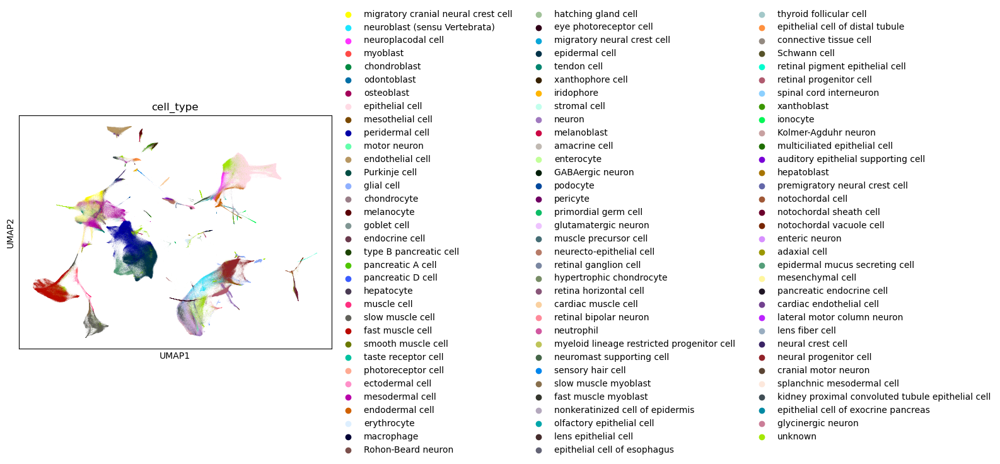

In [ ]:
sc.pl.umap(dr, color='cell_type')

In [ ]:
dr.obs['perturbation_id'].value_counts()

perturbation_id
na       869316
1,2,3    350862
Name: count, dtype: int64

In [ ]:
dr.obs['perturbation_strategy'].value_counts()

perturbation_strategy
na             869316
CRISPR-cas9    350862
Name: count, dtype: int64

In [ ]:
selected_perturb = [
    "na"
]

dr_sub = dr[
    dr.obs["perturbation_strategy"].isin(selected_perturb)
].copy()

In [ ]:
dr_sub

AnnData object with n_obs × n_vars = 869316 × 32031
    obs: 'Size_Factor', 'n.umi', 'perc_mitochondrial_umis', 'hash_umis', 'log.n.umi', 'top_to_second_best_ratio', 'projection_group', 'cell_type_long', 'cell_type_broad', 'num_genes_expressed', 'embryo_ID', 'perturbation', 'target', 'type', 'strain', 'expt', 'cross_batch', 'collection_batch', 'dis_protocol', 'fix_protocol', 'timepoint', 'cold_delay', 'subumap3d_1', 'subumap3d_2', 'subumap3d_3', 'mean_nn_time', 'cells_per_embryo', 'cell_type_ontology_term_id', 'donor_id', 'tissue_type', 'cell_line_ontology_term_id', 'perturbation_strategy', 'perturbation_role', 'perturbation_target_gene_id', 'perturbation_id', 'is_primary_data', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'assay_ontology_term_id', 'suspension_type', 'cell_type_short', 'publication', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnici

In [ ]:
pd.set_option("display.max_rows", None)
dr.obs['tissue'].value_counts()

tissue
multicellular anatomical structure    207173
periderm                              133504
skin epidermis                        121033
fast muscle tissue                     92619
hindbrain                              73401
genitourinary system                   42877
spinal cord                            35395
head                                   34325
pharyngeal arch                        33474
forebrain                              31841
slow muscle tissue                     30474
neural crest                           29282
retina                                 23503
somite                                 17523
lymphatic vessel endothelium           14478
median fin fold                        12746
dorsolateral placode                   12226
notochord                              11613
sclerotome                             11585
blood vessel endothelium               11277
integument                             10936
midbrain tectum                         9616
per

In [ ]:
selected_celltypes = [
    "slow muscle tissue",
    "somite",
    "fast muscle tissue",
    "presomitic mesoderm",
    "myotome",
    "craniocervical muscle",
    "hypaxial musculature"
]

In [ ]:
dr_sub2 = dr_sub[
    dr_sub.obs["tissue"].isin(selected_celltypes)
].copy()

In [ ]:
dr_sub2

AnnData object with n_obs × n_vars = 101871 × 32031
    obs: 'Size_Factor', 'n.umi', 'perc_mitochondrial_umis', 'hash_umis', 'log.n.umi', 'top_to_second_best_ratio', 'projection_group', 'cell_type_long', 'cell_type_broad', 'num_genes_expressed', 'embryo_ID', 'perturbation', 'target', 'type', 'strain', 'expt', 'cross_batch', 'collection_batch', 'dis_protocol', 'fix_protocol', 'timepoint', 'cold_delay', 'subumap3d_1', 'subumap3d_2', 'subumap3d_3', 'mean_nn_time', 'cells_per_embryo', 'cell_type_ontology_term_id', 'donor_id', 'tissue_type', 'cell_line_ontology_term_id', 'perturbation_strategy', 'perturbation_role', 'perturbation_target_gene_id', 'perturbation_id', 'is_primary_data', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'assay_ontology_term_id', 'suspension_type', 'cell_type_short', 'publication', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnici

In [ ]:
dr_sub2.obs['cell_type'].value_counts()

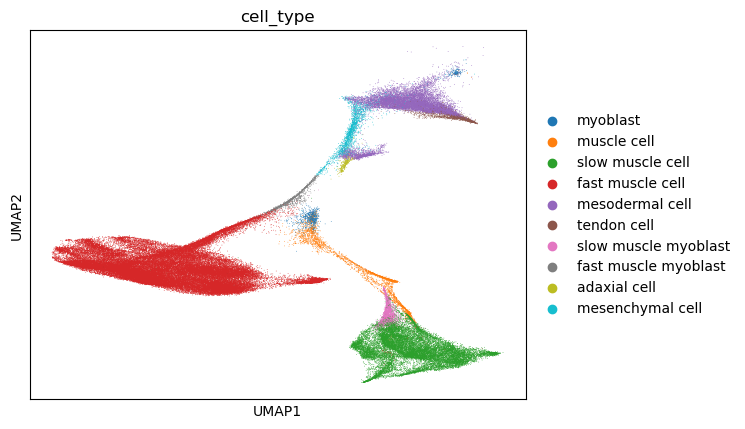

In [ ]:
sc.pl.umap(dr_sub2, color='cell_type')

In [ ]:
hs

AnnData object with n_obs × n_vars = 12376 × 36601
    obs: 'batch', 'percent_mito', 'n_counts', 'n_genes', 'doublet_scores', 'bh_pval', 'pre-annotation', 'region', 'tissue', 'adj_stage', 'adj_sample', 'leiden', 'S_score', 'G2M_score', 'phase', 'leiden_R', 'predicted_labels', 'over_clustering', 'majority_voting', 'conf_score', 'celltype', 'new_celltype', 'leiden_R_celltype', 'myogenesis_cluster', 'main_CT'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'ensembl_gene_id', 'gene_symbol', 'samap_gene'
    uns: 'adj_stage_colors', 'batch_colors', 'celltype_colors', 'celltype_sizes', 'leiden', 'leiden_R_celltype_colors', 'leiden_R_colors', 'leiden_sizes', 'log1p', 'majority_voting_colors', 'markers_celltype', 'markers_new_celltype', 'neighbors', 'new_celltype_colors', 'new_celltype_sizes', 'paga', 'pca', 'phase_colors', 'pre-annotation_colors', 'rank_genes_groups', 'region_colors', 'tissue_colors', 'umap'
    obsm: 'X_diffmap', 'X_draw_graph_fa', 'X_pca', 'X_umap'
    layers:

In [ ]:
mm

AnnData object with n_obs × n_vars = 305003 × 45525
    obs: 'donor_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'suspension_type', 'author_experimental_id', 'author_day', 'author_somite_count', 'author_major_cell_cluster', 'author_cell_type', 'tissue_type', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'gene_short_name', 'chr', 'start', 'end', 'strand', 'gene_type', 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type', 'ensembl_gene_id', 'gene_symbol', 'samap_gene'
    uns: 'author_day_colors', 'author_somite_count_colors', 'citation', 'is_pre_analysis', 'organism', 'organism_ontology_term_id', 'schema_reference', 'schema_version', 'title'
    obsm: 'X_u

## Preparation of raw expression matrices

SAMap performs its own preprocessing and normalization. Therefore, the input matrices should retain raw count information rather than only previously normalized expression values.

The different source datasets stored their expression matrices differently, so each AnnData object was inspected to determine where raw counts were located.

For the mouse dataset, the original .X contained normalized expression values, whereas the raw count matrix was available in .raw.X. The normalized matrix was therefore preserved in:

layers["X_normalized_original"]

and the raw count matrix was moved to .X.

The var_names of .X and .raw were also synchronized with the SAMap gene identifiers.

For zebrafish, .X already contained integer raw counts and could therefore be used directly.

Equivalent checks were also performed on the human dataset during its preparation.

The resulting processed H5AD files therefore provide consistent SAMap-ready objects while preserving normalized expression values when these were available.

In [ ]:
print(mm.var_names[:10])

print("raw available:", mm.raw is not None)

if mm.raw is not None:
    print(mm.raw.var_names[:10])

Index(['4933401J01Rik', 'Gm26206', 'Xkr4', 'Gm18956', 'Gm37180', 'Gm37363',
       'Gm37686', 'Gm1992', 'Gm37329', 'Gm7341'],
      dtype='str', name='gene_short_name')
raw available: True
Index(['ENSMUSG00000102693', 'ENSMUSG00000064842', 'ENSMUSG00000051951',
       'ENSMUSG00000102851', 'ENSMUSG00000103377', 'ENSMUSG00000104017',
       'ENSMUSG00000103025', 'ENSMUSG00000089699', 'ENSMUSG00000103201',
       'ENSMUSG00000103147'],
      dtype='str')


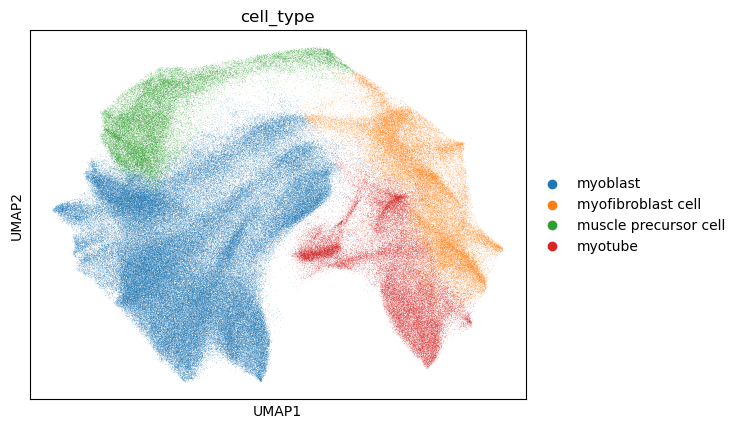

In [ ]:
sc.pl.umap(
    mm,
    color="cell_type",
    use_raw=False
)

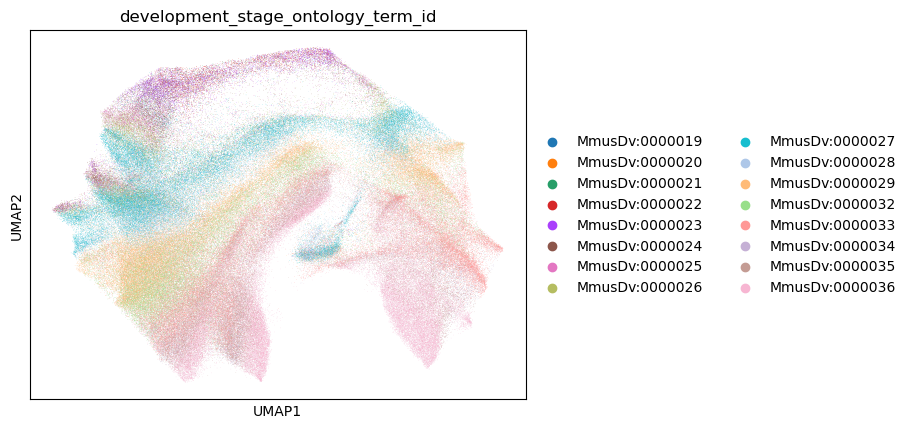

In [ ]:
sc.pl.umap(
    mm,
    color="development_stage_ontology_term_id",
    use_raw=False
)

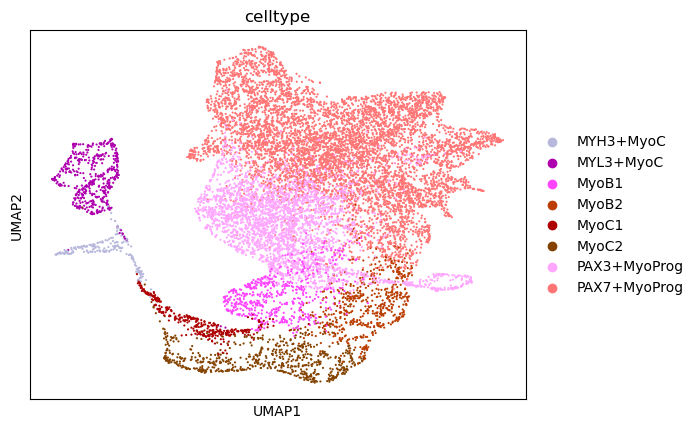

In [ ]:
sc.pl.umap(hs,color='celltype')

In [ ]:
hs.obs = hs.obs.copy()
hs.obs.index = hs.obs.index.astype(str)
hs.var.index = hs.var.index.astype(str)

hs.obs["celltype"] = hs.obs["celltype"].astype("category")

dr_sub2.obs = dr_sub2.obs.copy()
dr_sub2.obs.index = dr_sub2.obs.index.astype(str)
dr_sub2.var.index = dr_sub2.var.index.astype(str)

dr_sub2.obs["cell_type"] = dr_sub2.obs["cell_type"].astype("category")

mm.obs = mm.obs.copy()
mm.obs.index = mm.obs.index.astype(str)
mm.var.index = mm.var.index.astype(str)

mm.obs["cell_type"] = mm.obs["cell_type"].astype("category")

In [ ]:
mm.var_names

Index(['4933401J01Rik', 'Gm26206', 'Xkr4', 'Gm18956', 'Gm37180', 'Gm37363',
       'Gm37686', 'Gm1992', 'Gm37329', 'Gm7341',
       ...
       'mt-Nd4', 'mt-Th', 'mt-Ts2', 'mt-Tl2', 'mt-Nd5', 'mt-Nd6', 'mt-Te',
       'mt-Cytb', 'mt-Tt', 'mt-Tp'],
      dtype='str', name='gene_short_name', length=45525)

In [ ]:
res_hs = inspect_adata_matrices(
    hs,
    "HUMAN"
)

res_mm = inspect_adata_matrices(
    mm,
    "MOUSE"
)

res_dr = inspect_adata_matrices(
    dr_sub2,
    "ZEBRAFISH"
)



HUMAN

------------------------------------
HUMAN : X
------------------------------------
shape: (12376, 36601)
dtype: float32
sparse: True
fraction integer values: 1.0
minimum non-zero: 1.0
median non-zero: 1.0
maximum: 991.0
>>> seems value counts: True
total/cell median: 6645.0
total/cell range: 299.0 - 36028.0
corr with obs['n_counts']: 0.95376
relative error to the median: 0.25575

------------------------------------
HUMAN : layers['ambiguous']
------------------------------------
shape: (12376, 36601)
dtype: uint32
sparse: True
fraction integer values: 1.0
minimum non-zero: 1.0
median non-zero: 1.0
maximum: 195.0
>>> seems value counts: True
total/cell median: 678.0
total/cell range: 30 - 5907
corr with obs['n_counts']: 0.9891
relative error to the median: 0.92507

------------------------------------
HUMAN : layers['matrix']
------------------------------------
shape: (12376, 36601)
dtype: float32
sparse: True
fraction integer values: 1.0
minimum non-zero: 1.0
median non-zer

In [ ]:
print(hs.uns["log1p"])

{}


In [ ]:
hs.uns

{'adj_stage_colors': array(['#DF0029', '#EC870E', '#F1AF00', '#DCD800', '#5BBD2B', '#00B2BF',
        '#7388C1', '#511F90', '#79378B', '#8F006D'], dtype=object),
 'batch_colors': array(['#023fa5', '#7d87b9', '#bec1d4', '#d6bcc0', '#bb7784', '#8e063b',
        '#4a6fe3', '#8595e1', '#b5bbe3', '#e6afb9', '#e07b91', '#d33f6a',
        '#11c638', '#8dd593', '#c6dec7', '#ead3c6', '#f0b98d', '#ef9708',
        '#0fcfc0', '#9cded6', '#d5eae7', '#f3e1eb', '#f6c4e1', '#f79cd4',
        '#7f7f7f'], dtype=object),
 'celltype_colors': array(['#B8B8DC', '#AE00AE', '#FF44FF', '#BB3D00', '#AE0000', '#844200',
        '#ffa6ff', '#ff7575'], dtype=object),
 'celltype_sizes': array([ 6846,   900,   290,   434,    62,   443,    27,  4295,    90,
          367,   256,  3772,  5567,  1433,  2382,   164,  4631,  2334,
          110,   203,   588,    54,    47,    47, 11389,  9402,  3998,
         3970,  1860,  4217,   231,    37,   216,   715,   583,   574,
          339,   677,   433,    28,    41,  5378, 

In [ ]:
hs

AnnData object with n_obs × n_vars = 12376 × 36601
    obs: 'batch', 'percent_mito', 'n_counts', 'n_genes', 'doublet_scores', 'bh_pval', 'pre-annotation', 'region', 'tissue', 'adj_stage', 'adj_sample', 'leiden', 'S_score', 'G2M_score', 'phase', 'leiden_R', 'predicted_labels', 'over_clustering', 'majority_voting', 'conf_score', 'celltype', 'new_celltype', 'leiden_R_celltype', 'myogenesis_cluster', 'main_CT'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'ensembl_gene_id', 'gene_symbol', 'samap_gene'
    uns: 'adj_stage_colors', 'batch_colors', 'celltype_colors', 'celltype_sizes', 'leiden', 'leiden_R_celltype_colors', 'leiden_R_colors', 'leiden_sizes', 'log1p', 'majority_voting_colors', 'markers_celltype', 'markers_new_celltype', 'neighbors', 'new_celltype_colors', 'new_celltype_sizes', 'paga', 'pca', 'phase_colors', 'pre-annotation_colors', 'rank_genes_groups', 'region_colors', 'tissue_colors', 'umap'
    obsm: 'X_diffmap', 'X_draw_graph_fa', 'X_pca', 'X_umap'
    layers:

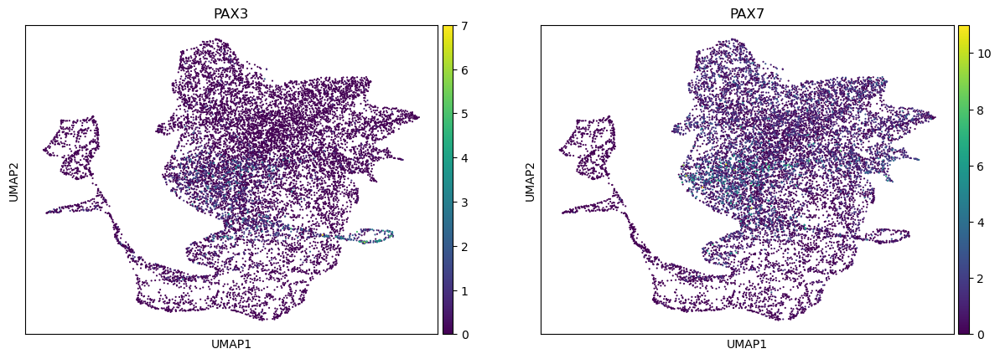

In [ ]:
sc.pl.umap(
    hs,
    color=["PAX3", "PAX7"],
    layer=None,
    use_raw=False
)

### Prepare the mouse count matrix

Preserve the original normalized expression in `layers["X_normalized_original"]`, place raw counts in `.X`, and synchronize the `.X` and `.raw` gene identifiers.

In [ ]:
mm.layers["X_normalized_original"] = mm.X.copy()

print(mm.layers["X_normalized_original"].shape)

(305003, 45525)


In [ ]:
# Confirm that raw counts and current features have identical order before copying.
if mm.raw is None:
    raise ValueError("The mouse dataset must contain raw counts in .raw.X.")
expected_raw_ids = pd.Index(mm.var["ensembl_gene_id"].astype(str))
if not expected_raw_ids.equals(mm.raw.var_names.astype(str)):
    raise ValueError("Mouse .raw features differ from the current feature order; align them before continuing.")
mm.X = mm.raw.X.copy()

In [ ]:
import numpy as np
import scipy.sparse as sp

vals = mm.X.data if sp.issparse(mm.X) else mm.X.ravel()
vals = vals[vals != 0]

print("min non-zero :", vals.min())
print("max :", vals.max())

print(
    "integer fraction :",
    np.mean(
        np.isclose(
            vals,
            np.round(vals)
        )
    )
)

min non-zero : 1.0
max : 3046.0
integer fraction : 1.0


In [ ]:
mm_raw = ad.AnnData(
    X=mm.X.copy(),
    obs=mm.obs.copy(),
    var=mm.var.copy()
)

mm_raw.var_names = mm.var_names.copy()

mm.raw = mm_raw

In [ ]:
mm

AnnData object with n_obs × n_vars = 305003 × 45525
    obs: 'donor_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'suspension_type', 'author_experimental_id', 'author_day', 'author_somite_count', 'author_major_cell_cluster', 'author_cell_type', 'tissue_type', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'gene_short_name', 'chr', 'start', 'end', 'strand', 'gene_type', 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type', 'ensembl_gene_id', 'gene_symbol', 'samap_gene'
    uns: 'author_day_colors', 'author_somite_count_colors', 'citation', 'is_pre_analysis', 'organism', 'organism_ontology_term_id', 'schema_reference', 'schema_version', 'title', 'cell_type_co

In [ ]:
print(mm.var_names[:10])
print(mm.raw.var_names[:10])
print(mm.var['gene_short_name'][:10])
print(mm.var['ensembl_gene_id'][:10])

Index(['4933401J01Rik', 'Gm26206', 'Xkr4', 'Gm18956', 'Gm37180', 'Gm37363',
       'Gm37686', 'Gm1992', 'Gm37329', 'Gm7341'],
      dtype='str', name='gene_short_name')
Index(['4933401J01Rik', 'Gm26206', 'Xkr4', 'Gm18956', 'Gm37180', 'Gm37363',
       'Gm37686', 'Gm1992', 'Gm37329', 'Gm7341'],
      dtype='str', name='gene_short_name')
gene_short_name
4933401J01Rik    4933401J01Rik
Gm26206                Gm26206
Xkr4                      Xkr4
Gm18956                Gm18956
Gm37180                Gm37180
Gm37363                Gm37363
Gm37686                Gm37686
Gm1992                  Gm1992
Gm37329                Gm37329
Gm7341                  Gm7341
Name: gene_short_name, dtype: category
Categories (45488, str): ['00R_AC107638.2', '00R_Pgap2', '0610005C13Rik', '0610006L08Rik', ..., 'n-R5s162', 'n-R5s173', 'n-R5s185', 'n-R5s204']
gene_short_name
4933401J01Rik    ENSMUSG00000102693
Gm26206          ENSMUSG00000064842
Xkr4             ENSMUSG00000051951
Gm18956          ENSMUSG00000

In [ ]:
print("=== MOUSE CHECK ===")

print("shape X :", mm.X.shape)
print("shape raw.X :", mm.raw.X.shape)

print(
    "var_names X == raw :",
    mm.var_names.equals(
        mm.raw.var_names
    )
)

print(
    "unique var_names:",
    mm.var_names.is_unique
)

print(
    "n layers :",
    list(mm.layers.keys())
)

print(
    "X_normalized_original :",
    mm.layers["X_normalized_original"].shape
)

=== MOUSE CHECK ===
shape X : (305003, 45525)
shape raw.X : (305003, 45525)
var_names X == raw : True
unique var_names: True
n layers : ['raw.X', None, 'X_normalized_original']
X_normalized_original : (305003, 45525)


In [ ]:
mm.var.index.name = "samap_gene"
raw_tmp = mm.raw.to_adata()

raw_tmp.var.index.name = "samap_gene"

mm.raw = raw_tmp

In [ ]:
print("X var index name   :", mm.var.index.name)
print("raw var index name :", mm.raw.var.index.name)

print(
    "identical var_names:",
    mm.var_names.equals(mm.raw.var_names)
)

X var index name   : samap_gene
raw var index name : samap_gene
identical var_names: True


In [ ]:
dr_sub2.var.index.name = "samap_gene"

if dr_sub2.raw is not None:
    raw_tmp = dr_sub2.raw.to_adata()
    raw_tmp.var.index.name = "samap_gene"
    dr_sub2.raw = raw_tmp

In [ ]:
hs.var.index.name = "samap_gene"

if hs.raw is not None:
    raw_tmp = hs.raw.to_adata()
    raw_tmp.var.index.name = "samap_gene"
    hs.raw = raw_tmp

### Save the prepared H5AD datasets

In [ ]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
hs.write_h5ad(HUMAN_READY_PATH)
mm.write_h5ad(MOUSE_READY_PATH)
dr_sub2.write_h5ad(ZEBRAFISH_READY_PATH)

In [6]:
hs = sc.read_h5ad(HUMAN_READY_PATH)
mm = sc.read_h5ad(MOUSE_READY_PATH)
dr_sub2 = sc.read_h5ad(ZEBRAFISH_READY_PATH)

## Mouse reanalysis and manual annotation

Two explicit routes replace the original mixture of fresh analysis and late checkpoint loading:

- **Default (`REBUILD_MOUSE_ANNOTATION = False`):** load `MOUSE_ANNOTATED_PATH` before inspecting the reannotated mouse dataset. Reuse its manual `cell_type` labels, Leiden clusters, UMAP, normalized layers, and existing gene scores.
- **Rebuild (`True`):** start from the prepared mouse counts and rerun the original normalization, PCA, neighborhood graph, Leiden clustering, and UMAP settings. Review cluster markers and supply the complete verified `MANUAL_ANNOTATIONS` mapping before exporting or integrating.

The supplied annotation cell contains only example labels for clusters 0–2. It does not record the actual manual mapping. Those examples are not used as biological annotations. Without the saved annotated H5AD or a verified mapping, the final manual annotation cannot be reconstructed faithfully.

In [7]:
if REBUILD_MOUSE_ANNOTATION:
    re = mm.copy()
    # mm.X contains the raw counts prepared above.
    re.layers["raw.X"] = re.X.copy()
    re.obsm["X_umap_original"] = mm.obsm["X_umap"].copy()
else:
    if not MOUSE_ANNOTATED_PATH.is_file():
        raise FileNotFoundError(
            f"Annotated mouse checkpoint not found: {MOUSE_ANNOTATED_PATH}. "
            "Provide the saved H5AD, or enable rebuilding and supply verified manual annotations."
        )
    re = sc.read_h5ad(MOUSE_ANNOTATED_PATH)
    required_obs = {"cell_type", "cell_type_origin", "leiden_re_0.4", "author_day"}
    missing_obs = required_obs.difference(re.obs.columns)
    missing_layers = {"raw.X", "LogNorm", "X_normalized_original"}.difference(re.layers.keys())
    if missing_obs or missing_layers or "X_umap" not in re.obsm:
        raise ValueError(
            f"Incomplete annotated checkpoint: missing obs={sorted(missing_obs)}, "
            f"layers={sorted(missing_layers)}, X_umap={'X_umap' not in re.obsm}."
        )

### Original mouse UMAP and raw marker expression

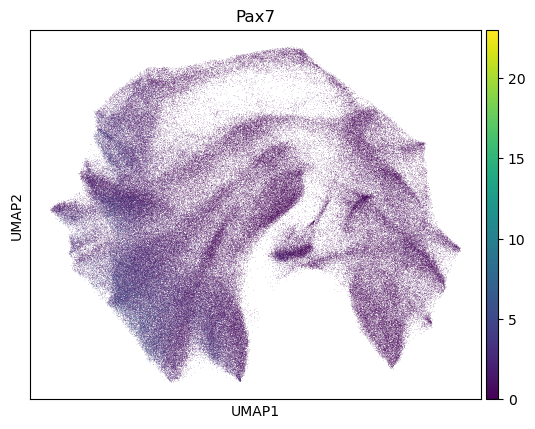

In [ ]:
sc.pl.umap(
    mm,
    color="Pax7",
    use_raw=False
)

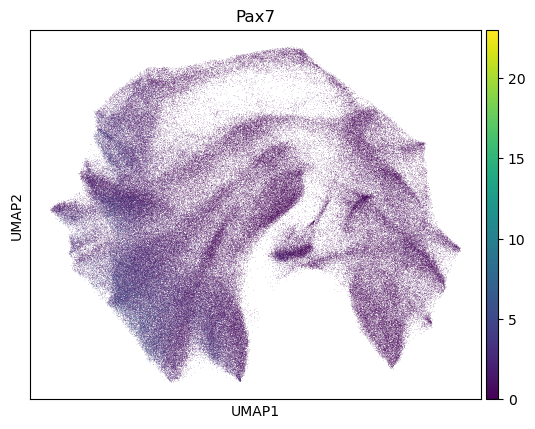

In [ ]:
sc.pl.umap(
    re,
    color="Pax7",
    use_raw=False
)

/home/sabrina/anaconda3/envs/SAMapv3/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


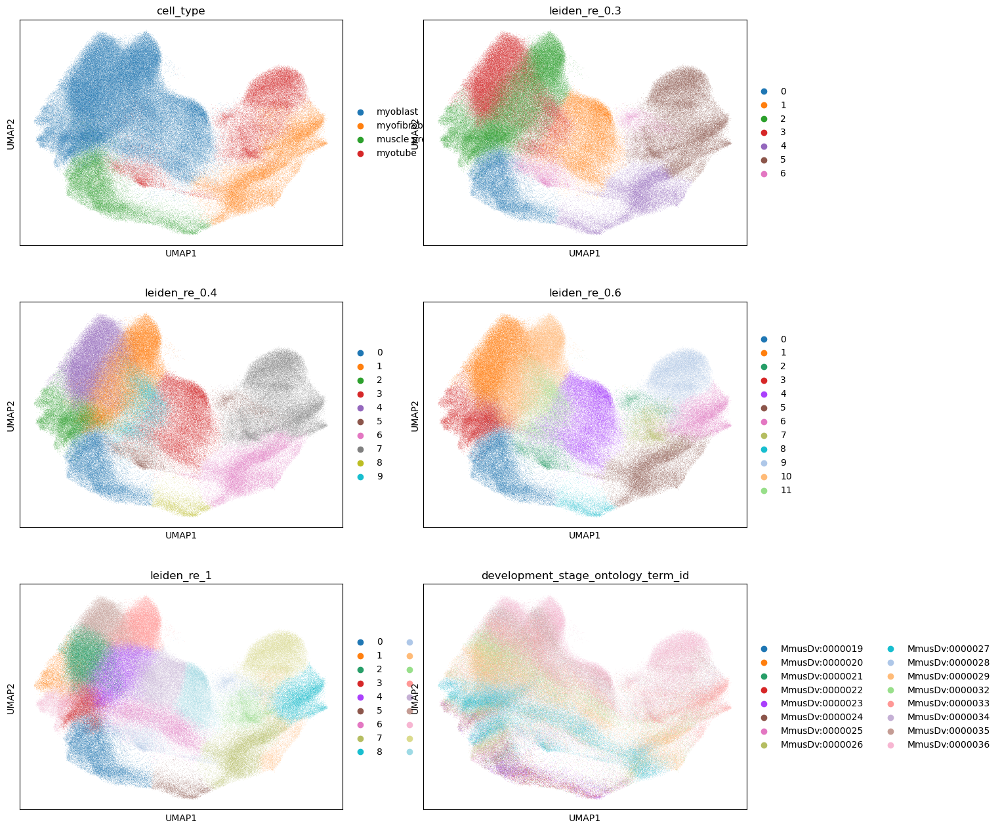

In [8]:
if REBUILD_MOUSE_ANNOTATION:
    # Per-cell normalization, followed by log(1 + x)
    sc.pp.normalize_total(re, target_sum=1e4)
    sc.pp.log1p(re)

    # Select highly variable genes without removing other genes
    sc.pp.highly_variable_genes(
        re,
        flavor="seurat",
        n_top_genes=4000,
        subset=False,
    )

    # PCA on highly variable genes, without explicit densification
    # Syntax for Scanpy >= 1.10
    sc.pp.pca(
        re,
        n_comps=50,
        mask_var="highly_variable",
        svd_solver="arpack",
        random_state=0,
    )

    # Construct the neighborhood graph in PCA space
    sc.pp.neighbors(
        re,
        n_neighbors=30,
        n_pcs=50,
        use_rep="X_pca",
        random_state=0,
    )

    # Clustering at several resolutions
    for resolution in [0.3, 0.6, 0.4, 1.0]:
        sc.tl.leiden(
            re,
            resolution=resolution,
            key_added=f"leiden_re_{resolution:g}",
            flavor="igraph",
            directed=False,
            n_iterations=2,
            random_state=0,
        )

    sc.tl.umap(re, random_state=0)

    sc.pl.umap(
        re,
        color=["cell_type", "leiden_re_0.3", "leiden_re_0.4", "leiden_re_0.6", "leiden_re_1", 'development_stage_ontology_term_id'],
        ncols=2,
    )

In [9]:
if REBUILD_MOUSE_ANNOTATION:
    # Store the newly computed normalized expression before marker plots.
    re.layers["LogNorm"] = re.X.copy()
    sc.tl.rank_genes_groups(
        re,
        groupby="leiden_re_0.4",
        method="wilcoxon",
        use_raw=False,
        layer="LogNorm",
        pts=True,
        key_added="markers_by_leiden_re_0.4",
    )
    cluster_markers = sc.get.rank_genes_groups_df(
        re, key="markers_by_leiden_re_0.4", group=None
    )
    display(cluster_markers)

,group,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,pct_nz_reference
0,0,Fat3,236.455582,4.392548,0.0,0.0,0.955668,0.346356
1,0,Gpc6,225.462616,3.948406,0.0,0.0,0.978151,0.570395
2,0,Adgrb3,172.241806,3.519695,0.0,0.0,0.775417,0.266837
3,0,Efna5,167.920822,2.679548,0.0,0.0,0.893682,0.489766
4,0,Cadm1,162.627655,3.300666,0.0,0.0,0.751489,0.266092
...,...,...,...,...,...,...,...,...
455245,9,Mbnl2,-61.244450,-1.402501,0.0,0.0,0.414921,0.607658
455246,9,Tspan9,-65.224625,-2.432392,0.0,0.0,0.149943,0.432636
455247,9,Palld,-69.630531,-2.174477,0.0,0.0,0.383935,0.583386
455248,9,Ank3,-77.932068,-2.047887,0.0,0.0,0.348893,0.615794


### Inspect mouse embeddings and marker expression

In [10]:
re

AnnData object with n_obs × n_vars = 305003 × 45525
    obs: 'donor_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'suspension_type', 'author_experimental_id', 'author_day', 'author_somite_count', 'author_major_cell_cluster', 'author_cell_type', 'tissue_type', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'leiden_re_0.3', 'leiden_re_0.6', 'leiden_re_0.4', 'leiden_re_1'
    var: 'gene_short_name', 'chr', 'start', 'end', 'strand', 'gene_type', 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type', 'ensembl_gene_id', 'gene_symbol', 'samap_gene', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'author_day_colors', 'author_somite_count_colors', 'ce

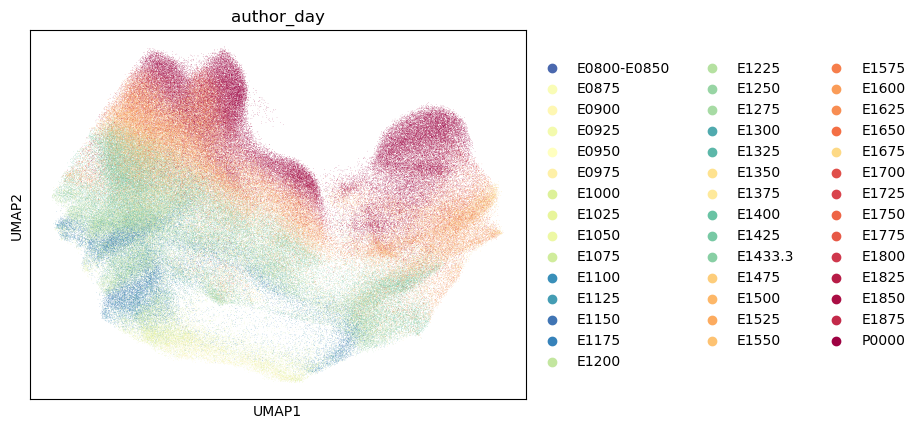

In [11]:
sc.pl.umap(
    re,
    color=['author_day'],
    ncols=2,
)

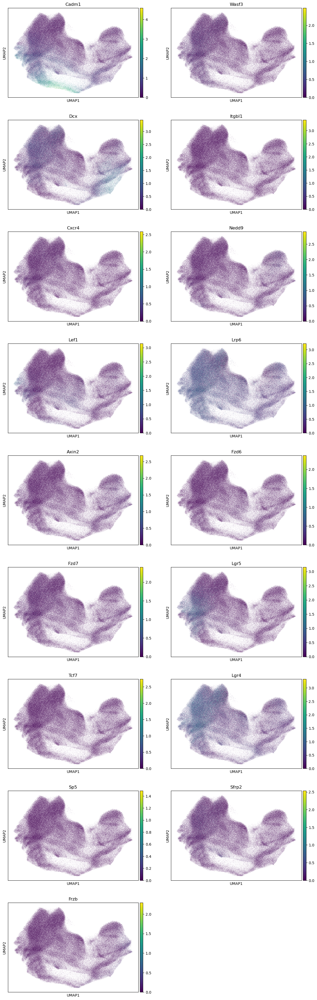

In [ ]:
sc.pl.umap(
    re,
    color=["Cadm1", "Wasf3", "Dcx", "Itgbl1", "Cxcr4", "Nedd9",
                   "Lef1", "Lrp6", "Axin2", "Fzd6", "Fzd7", "Lgr5", "Tcf7", "Lgr4", "Sp5",
                   "Sfrp2","Frzb"],
    ncols=2,
    layer ='X_normalized_original'
)

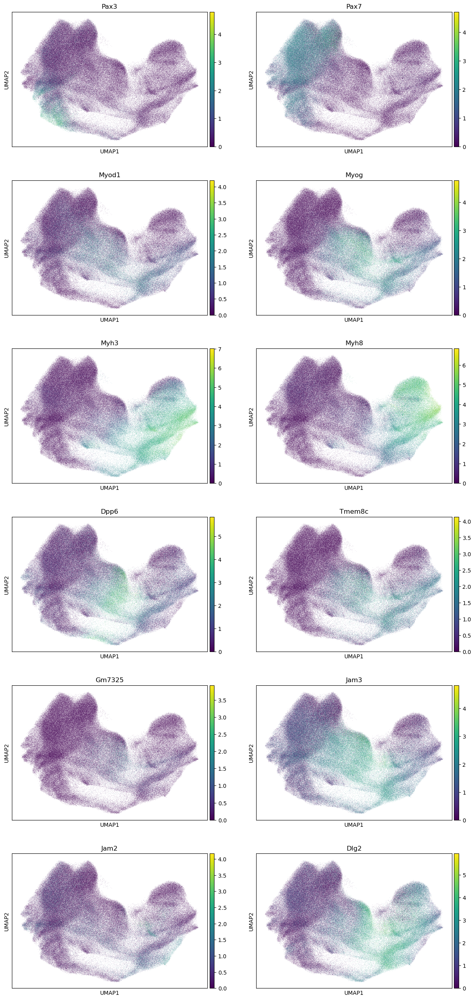

In [12]:
sc.pl.umap(
    re,
    color=["Pax3", "Pax7", 'Myod1', 'Myog', 'Myh3', 'Myh8', 'Dpp6','Tmem8c', 'Gm7325', 'Jam3', 'Jam2', 'Dlg2' ],
    ncols=2,
    layer ='LogNorm'
)

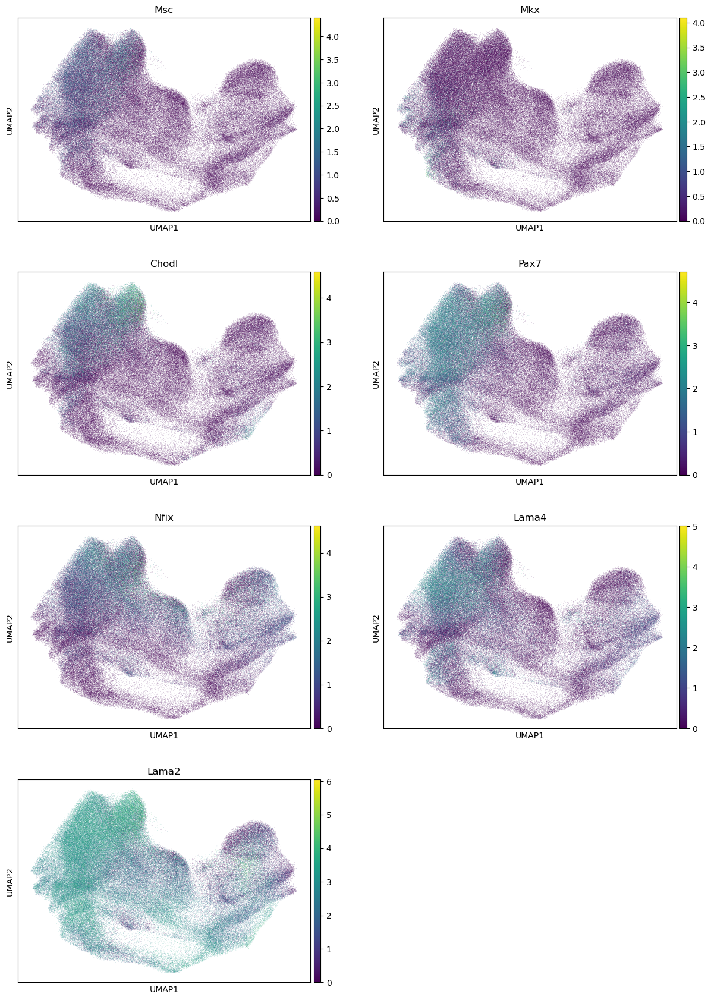

In [ ]:
sc.pl.umap(
    re,
    color=["Msc", "Mkx", "Chodl", "Pax7", "Nfix", "Lama4", "Lama2"],
    ncols=2,
    layer ='LogNorm'
)

In [13]:
re

AnnData object with n_obs × n_vars = 305003 × 45525
    obs: 'donor_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'suspension_type', 'author_experimental_id', 'author_day', 'author_somite_count', 'author_major_cell_cluster', 'author_cell_type', 'tissue_type', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'leiden_re_0.3', 'leiden_re_0.6', 'leiden_re_0.4', 'leiden_re_1'
    var: 'gene_short_name', 'chr', 'start', 'end', 'strand', 'gene_type', 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type', 'ensembl_gene_id', 'gene_symbol', 'samap_gene', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'author_day_colors', 'author_somite_count_colors', 'ce

### Myogenesis gene-set scores

Gene lists, duplicate entries, spellings, and scoring defaults are retained from the source notebook; no unverified gene substitutions were made. Existing checkpoint scores are kept. Scores are computed when missing, or when rebuilding. The original default choice of `.raw` for scoring, when available, is unchanged.

In [14]:
#-------------------------------Cell scores plot for myogenesis waves in human limb dev paper and chiken forelimb dev ------------------
# Centered non-symmetric palette

# Calculate the myogenesis gene-set scores
if REBUILD_MOUSE_ANNOTATION or 'SndMyo_cell_score' not in re.obs:
    sc.tl.score_genes(re, ["Klf4","Fosb", "Stat5a", "Etv2", "Maf","Irf1", "Nfic", "Nr3c1", "Cebpd",
                             "Nfia", "Hoxb2", "Hic1", "Osr2", "Etv4", "E2f1", "Etv5", "Znf556", "Hoxb2","Irf3", "Myf6"], score_name="SndMyo_cell_score")

if REBUILD_MOUSE_ANNOTATION or 'PriMyo_cell_score' not in re.obs:
    sc.tl.score_genes(re, ["Msx1","Hoxd9", "Mxd3", "Znf749", "Bcl11a", "Tbx3", "Six2", "Barx2", "Cux2","Pou2f2",
                              "Gata3","Pitx2", "Rxrg"], score_name="PriMyo_cell_score")


if REBUILD_MOUSE_ANNOTATION or 'Toulouse_geneSet' not in re.obs:
    sc.tl.score_genes(re, ["Epah7", "Cadm1", "Wasf3", "Dcx", "Itgbl1", "Cxcr4", "Nedd9",
                       "Lef1", "Lrp6", "Axin2", "Fzd6", "Fzd7", "Lgr5", "Tcf7", "Lgr4", "Sp5",
                       "Sfrp2","Frzb"], score_name='Toulouse_geneSet')



#sc.tl.score_genes(adata, ["PITX1", "BRCA1", "PAX7", "ZNF367", "E2F2"], score_name="TransMyo_cell_score")


# Palette normalization with centering and adapted dynamic range to correspond to
# the distance of vmin and vmax from the cenetr
# Adapted from https://stackoverflow.com/a/50003503
class MidpointNormalize(mcolors.Normalize):
    def __init__(self, vmin=None, vmax=None, midpoint=0, clip=False):
        self.midpoint = midpoint
        mcolors.Normalize.__init__(self, vmin, vmax, clip)

    def __call__(self, value, clip=None):
        value = np.array(value).astype(float)
        normalized_min = max(
            0.0,
            0.5
            * (1.0 - abs((self.midpoint - self.vmin) / (self.midpoint - self.vmax))),
        )
        normalized_max = min(
            1.0,
            0.5
            * (1.0 + abs((self.vmax - self.midpoint) / (self.midpoint - self.vmin))),
        )
        normalized_mid = 0.5
        x, y = (
            [self.vmin, self.midpoint, self.vmax],
            [normalized_min, normalized_mid, normalized_max],
        )
        return np.ma.masked_array(np.interp(value, x, y))


# Add padding arround vmin and vmax as Colorbar sets value limits to round numbers below and
# above the vmin and vmax, respectively, which means that they can not be assigned the correct
# color with our nomalisation function that is limited to vmin and vmax
# However, this padding reduces the dynamic range as we set a broad padding and
# then later discard values that are not needed for the rounding up and down
# of the vmin and vmax on the Colorbar, respectively

(-4.0, 8.0)

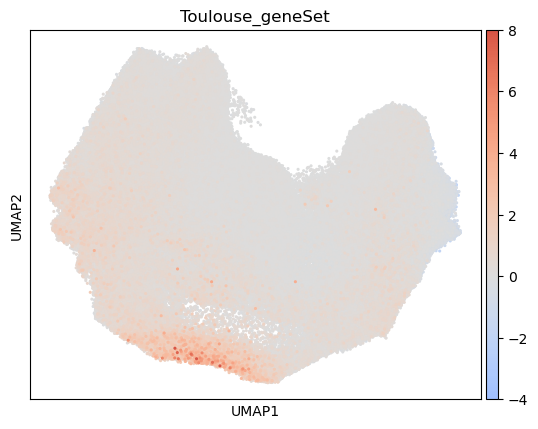

In [15]:
# plot secondary myogenesis cell score

vmin = re.obs["Toulouse_geneSet"].min()
vmax = re.obs["Toulouse_geneSet"].max()
vpadding = (vmax - vmin) * 0.2
norm = MidpointNormalize(vmin=vmin - vpadding, vmax=vmax + vpadding, midpoint=0)
# Plot umap
fig = sc.pl.umap(
    re,
    color="Toulouse_geneSet",
    cmap="coolwarm",
    s=20,
    norm=norm,
    return_fig=True,
    show=False,
)
# Adjust Colorbar ylim to be just outside of vmin,vmax and not far outside of this range
# as the padding we set initially may be too broad
cmap_yticklabels = np.array([t._y for t in fig.axes[1].get_yticklabels()])
fig.axes[1].set_ylim(
    max(cmap_yticklabels[cmap_yticklabels < vmin]),
    min(cmap_yticklabels[cmap_yticklabels > vmax]),
)

#adata.obs.drop("SndMyo_cell_score", axis=1, inplace=True)

(-2.0, 8.0)

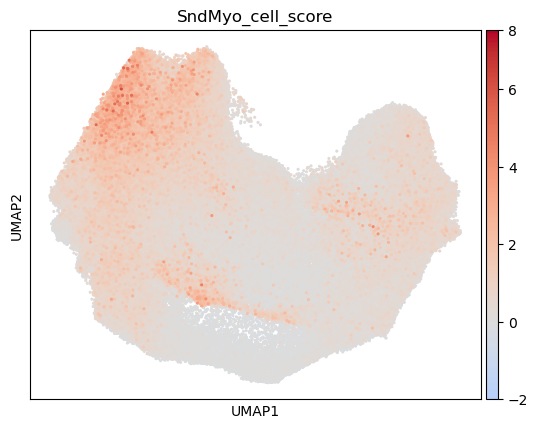

In [16]:
# plot secondary myogenesis cell score

vmin = re.obs["SndMyo_cell_score"].min()
vmax = re.obs["SndMyo_cell_score"].max()
vpadding = (vmax - vmin) * 0.2
norm = MidpointNormalize(vmin=vmin - vpadding, vmax=vmax + vpadding, midpoint=0)
# Plot umap
fig = sc.pl.umap(
    re,
    color="SndMyo_cell_score",
    cmap="coolwarm",
    s=20,
    norm=norm,
    return_fig=True,
    show=False,
)
# Adjust Colorbar ylim to be just outside of vmin,vmax and not far outside of this range
# as the padding we set initially may be too broad
cmap_yticklabels = np.array([t._y for t in fig.axes[1].get_yticklabels()])
fig.axes[1].set_ylim(
    max(cmap_yticklabels[cmap_yticklabels < vmin]),
    min(cmap_yticklabels[cmap_yticklabels > vmax]),
)

#adata.obs.drop("SndMyo_cell_score", axis=1, inplace=True)

(-1.0, 4.0)

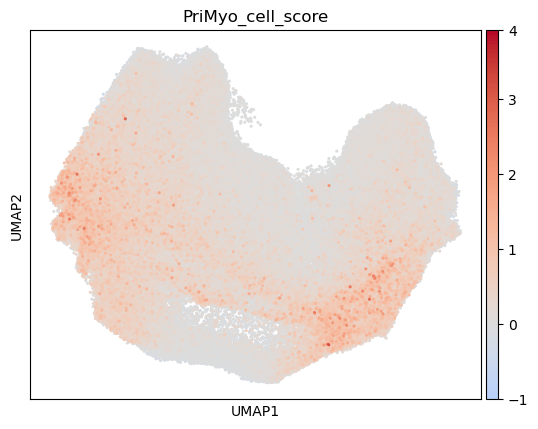

In [17]:
# plot primary myogenesis cell score

vmin = re.obs["PriMyo_cell_score"].min()
vmax = re.obs["PriMyo_cell_score"].max()
vpadding = (vmax - vmin) * 0.2
norm = MidpointNormalize(vmin=vmin - vpadding, vmax=vmax + vpadding, midpoint=0)
# Plot umap
fig = sc.pl.umap(
    re,
    color="PriMyo_cell_score",
    cmap="coolwarm",
    s=20,
    norm=norm,
    return_fig=True,
    show=False,
)
# Adjust Colorbar ylim to be just outside of vmin,vmax and not far outside of this range
# as the padding we set initially may be too broad
cmap_yticklabels = np.array([t._y for t in fig.axes[1].get_yticklabels()])
fig.axes[1].set_ylim(
    max(cmap_yticklabels[cmap_yticklabels < vmin]),
    min(cmap_yticklabels[cmap_yticklabels > vmax]),
)

### Apply verified manual annotations

In checkpoint mode, keep the saved `cell_type` labels unchanged. In rebuild mode, every Leiden cluster must have a verified label. Missing labels stop execution before the annotated dataset is saved or used for SAMap; no example labels or generic cluster names are substituted.

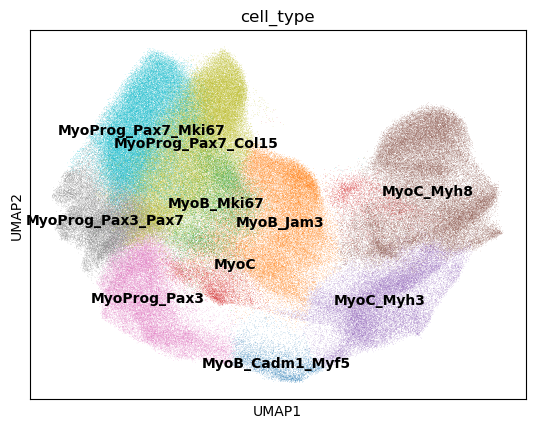

In [18]:
if REBUILD_MOUSE_ANNOTATION:
    clusters = re.obs["leiden_re_0.4"].astype(str)
    missing_clusters = sorted(set(clusters) - set(MANUAL_ANNOTATIONS))
    invalid_labels = [
        cluster for cluster, label in MANUAL_ANNOTATIONS.items()
        if not isinstance(label, str) or not label.strip()
        or label.startswith(("Cell_type_", "Cluster "))
    ]
    if missing_clusters or invalid_labels:
        raise ValueError(
            f"Verified manual annotations required. Missing clusters: {missing_clusters}; "
            f"invalid labels for: {invalid_labels}. Review markers before completing the mapping."
        )
    re.obs["cell_type_re_0.4"] = clusters.map(MANUAL_ANNOTATIONS).astype("category")
    re.obs.rename(
        columns={"cell_type": "cell_type_origin", "cell_type_re_0.4": "cell_type"},
        inplace=True,
    )
    if "cell_type_colors" in re.uns:
        re.uns["cell_type_origin_colors"] = re.uns.pop("cell_type_colors")
    if "cell_type_re_0.4_colors" in re.uns:
        re.uns["cell_type_colors"] = re.uns.pop("cell_type_re_0.4_colors")
sc.pl.umap(re, color="cell_type", legend_loc="on data")

### Markers and expression summaries for the final mouse annotations

In [19]:
sc.tl.rank_genes_groups(
    re,
    groupby="cell_type",
    method="wilcoxon",
    use_raw=False,
    layer='LogNorm',
    pts=True,
    key_added="marker_re"

)

In [23]:
rank_df = sc.get.rank_genes_groups_df(re, key="marker_re", group=None)

In [24]:
filtered_rank_df = rank_df.dropna(subset=['logfoldchanges'])
print(filtered_rank_df.head())

# Difference between the fractions of expressing cells in the cluster and the reference
rank_df['diff_pct'] = rank_df['pct_nz_group'] - rank_df['pct_nz_reference']

# Keep genes with a difference of at least 0.20 (20 percentage points) and a positive log fold change
filtered_df = rank_df[(rank_df['diff_pct'] >= 0.20) & (rank_df['logfoldchanges'] > 0)]

# Sort all rows by adjusted p-value, then decreasing log fold change and expressing-cell fraction
filtered_df = filtered_df.sort_values(by=['pvals_adj', 'logfoldchanges', 'pct_nz_group'], ascending=[True, False, False])

# Display the first 50 rows of the globally sorted table (not 50 per cluster)
top50_df = filtered_df.head(50)

# Display the result
print(top50_df)

             group     names      scores  logfoldchanges  pvals  pvals_adj  \
0  MyoB_Cadm1_Myf5    Clstn2  113.880157        7.049266    0.0        0.0   
1  MyoB_Cadm1_Myf5  Cacna2d1  104.226265        3.223530    0.0        0.0   
2  MyoB_Cadm1_Myf5     Palld  103.017494        4.308033    0.0        0.0   
3  MyoB_Cadm1_Myf5     Cadm1  101.148979        4.840281    0.0        0.0   
4  MyoB_Cadm1_Myf5     Mef2c  100.685951        4.323007    0.0        0.0   

   pct_nz_group  pct_nz_reference  
0      0.997137          0.267184  
1      0.996476          0.740827  
2      0.994493          0.567191  
3      0.961674          0.301425  
4      0.992511          0.446444  
                  group          names      scores  logfoldchanges  pvals  \
6       MyoB_Cadm1_Myf5          Prdm1   90.713448        8.078844    0.0   
227660        MyoC_Myh8           Mlip  226.427109        7.131757    0.0   
0       MyoB_Cadm1_Myf5         Clstn2  113.880157        7.049266    0.0   
227787 

In [25]:
filtered_df.to_csv("Marker_annot_df.csv", sep="\t", index=True)

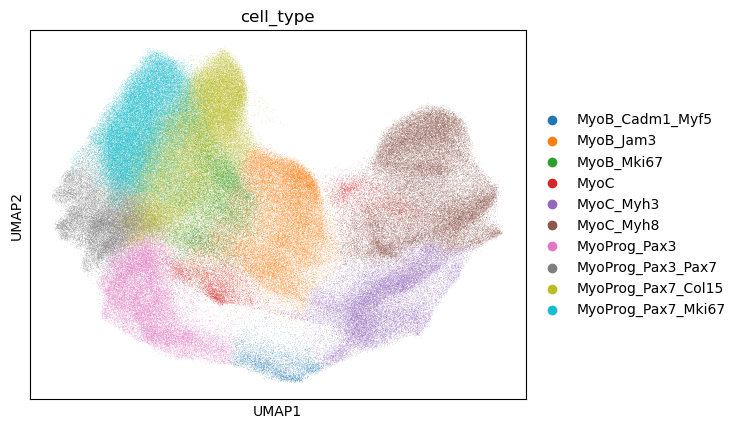

In [26]:
sc.pl.umap(re, color=[ "cell_type"])

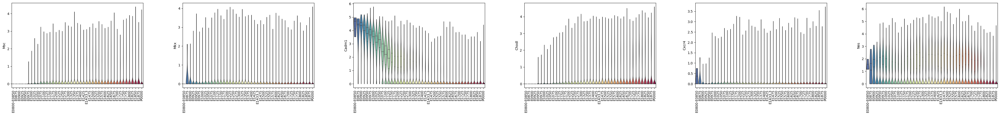

In [27]:
sc.pl.violin(
    re,
    groupby="author_day",#''
    keys=["Msc", "Mkx", "Cadm1", "Chodl", "Cxcr4", "Nes"],
    use_raw=False,
    layer='LogNorm',
    rotation=90,
    dodge=False,       # Center the violins and prevent narrowing
    stripplot=False,   # Hide overlaid points
    cut=0,            # Restrict the density to the observed value range
    inner="quartile",
    linewidth=1,
)

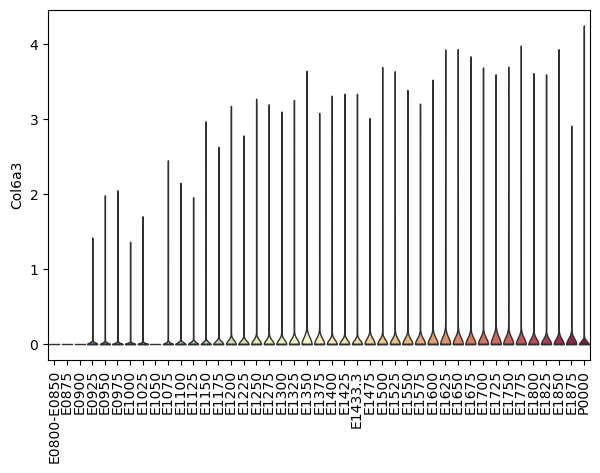

In [28]:
sc.pl.violin(
    re,
    groupby="author_day",#'author_day'
    keys=["Col6a3"],
    use_raw=False,
    layer="LogNorm",
    rotation=90,
    dodge=False,       # Center the violins and prevent narrowing
    stripplot=False,   # Hide overlaid points
    cut=0,            # Restrict the density to the observed value range
    inner="quartile",
    linewidth=1,
)

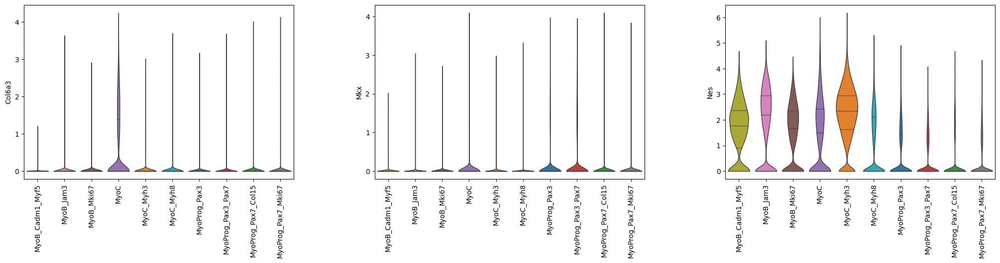

In [29]:
sc.pl.violin(
    re,
    groupby="cell_type",#'author_day'
    keys=["Col6a3", "Mkx","Nes"],
    use_raw=False,
    layer="LogNorm",
    rotation=90,
    dodge=False,       # Center the violins and prevent narrowing
    stripplot=False,   # Hide overlaid points
    cut=0,            # Restrict the density to the observed value range
    inner="quartile",
    linewidth=1,
)

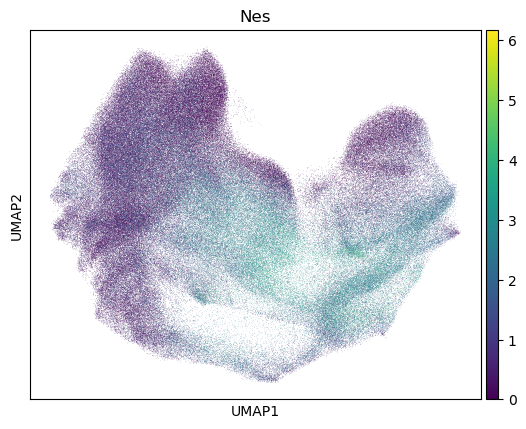

In [ ]:
sc.pl.umap(
    re,
    color=['Nes' ],
    ncols=2,
    layer ='LogNorm'
)

### Export the reannotated mouse dataset for SAMap

Preserve `LogNorm`; do not overwrite it with `.X` from a checkpoint that may already contain counts. Restore `.X` from `layers["raw.X"]` only after the expression plots and marker analyses. The exported path is the same path used for the annotated mouse input below.

In [30]:
re.X = re.layers["raw.X"].copy()
re.write_h5ad(MOUSE_ANNOTATED_PATH)

In [31]:
re

AnnData object with n_obs × n_vars = 305003 × 45525
    obs: 'donor_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'suspension_type', 'author_experimental_id', 'author_day', 'author_somite_count', 'author_major_cell_cluster', 'author_cell_type', 'tissue_type', 'is_primary_data', 'cell_type_origin', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'leiden_re_0.3', 'leiden_re_0.6', 'leiden_re_0.4', 'leiden_re_1', 'SndMyo_cell_score', 'PriMyo_cell_score', 'Toulouse_geneSet', 'cell_type'
    var: 'gene_short_name', 'chr', 'start', 'end', 'strand', 'gene_type', 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type', 'ensembl_gene_id', 'gene_symbol', 'samap_gene', 'highly_variable', 'means', 'dispersions', 

## Mouse–zebrafish SAMap integration

SAMap was run using the prepared mouse and zebrafish H5AD objects together with the reciprocal sequence-based gene maps.

The analysis contains approximately:

305,000 mouse cells
102,000 zebrafish cells

for a combined dataset of approximately 407,000 cells.

During SAMap initialization, approximately 29,000 mouse genes and 23,000 zebrafish genes could be connected to the sequence homology graph.

SAMap then iteratively refines the cross-species manifold by combining transcriptomic similarity and sequence homology. Across the three iterations, the global alignment increased progressively, indicating convergence toward a more coherent cross-species representation.

Cell-type relationships were subsequently quantified using the saved manual mouse cell_type annotations and the curated zebrafish cell_type annotations.

In [4]:
fn1 = str(MOUSE_ANNOTATED_PATH)
fn2 = str(ZEBRAFISH_READY_PATH)

In [5]:
filenames = {'mm':fn1, 'dr':fn2}

In [6]:
keys = {'mm':'cell_type', 'dr':'cell_type'} #'hs':'celltype',

In [7]:
for sid, path in filenames.items():
    print("\n", sid, "→", path)
    input_adata = sc.read_h5ad(path)
    print("  shape:", input_adata.shape)
    print("  n_vars:", input_adata.n_vars)
    print("  len(var_names):", len(input_adata.var_names))


 mm → /home/sabrina/Documents/BioHack26/samap_3species/data/processed_h5ad/mouse_annot_SKM_samap_ready.h5ad
  shape: (305003, 45525)
  n_vars: 45525
  len(var_names): 45525

 dr → /home/sabrina/Documents/BioHack26/samap_3species/data/processed_h5ad/zebrafish_SKM_samap_ready.h5ad
  shape: (101871, 32031)
  n_vars: 32031
  len(var_names): 32031


In [8]:
sm = SAMAP(filenames, f_maps=str(MAPS_DIR) + "/")

INFO: Using backend: cpu
INFO: Processing data mm from: /home/sabrina/Documents/BioHack26/samap_3species/data/processed_h5ad/mouse_annot_SKM_samap_ready.h5ad
INFO: Running SAM algorithm
INFO: Iteration: 0, Convergence: 1.000000
INFO: Iteration: 1, Convergence: 0.906616
INFO: Iteration: 2, Convergence: 0.013326
INFO: Elapsed time: 273.48 seconds
INFO: Not updating the manifold...
INFO: Processing data dr from: /home/sabrina/Documents/BioHack26/samap_3species/data/processed_h5ad/zebrafish_SKM_samap_ready.h5ad
INFO: Running SAM algorithm
INFO: Iteration: 0, Convergence: 1.000000
INFO: Iteration: 1, Convergence: 0.897674
INFO: Iteration: 2, Convergence: 0.010683
INFO: Elapsed time: 69.01 seconds
INFO: Not updating the manifold...
INFO: 29351 'mm' gene symbols match between the datasets and the BLAST graph.
INFO: 23148 'dr' gene symbols match between the datasets and the BLAST graph.


In [9]:
sm.run()
samap = sm.samap

INFO: Prepping datasets for translation.
INFO: Translating feature spaces pairwise.
INFO: Projecting data into joint latent space. 49.87s
INFO: Correcting data with means. 0.47s
INFO: Expanding neighbourhoods of species mm...
INFO: Expanding neighbourhoods of species dr...
INFO: Indegree coarsening
INFO: Rescaling edge weights by expression correlations.
INFO: Concatenating SAM objects...
INFO: Iteration 1 complete.
INFO: Alignment scores:
          dr        mm
dr  0.000000  0.619331
mm  0.533249  0.000000
INFO: Calculating gene-gene correlations in the homology graph...
INFO: Correlation: estimated Xavg 100.699 GB (density~45.6%, 406874 cells x 45189 genes) >= 2.0 GB threshold — using streaming path (batch_size=512).
INFO: Prepping datasets for translation.
INFO: Translating feature spaces pairwise.
INFO: Projecting data into joint latent space. 57.55s
INFO: Correcting data with means. 0.54s
INFO: Expanding neighbourhoods of species mm...
INFO: Expanding neighbourhoods of species dr.

In [10]:
D, MappingTable = get_mapping_scores(sm, keys, n_top=0)

In [11]:
# Save mapping tables using the original delimiter and index settings.
SAMAP_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
df = pd.DataFrame(D)
df1 = pd.DataFrame(MappingTable)
df.to_csv(SAMAP_OUTPUT_DIR / "MappingD_mm_dr_annot.csv", sep="\t", index=False)
df1.to_csv(SAMAP_OUTPUT_DIR / "MappingT_mm_dr_annot.csv", sep="\t", index=False)

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
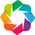

:Sankey   [source,target]   (Value)

In [12]:
# Interactive sankey plot

import numpy as np
import pandas as pd
import holoviews as hv
hv.extension('bokeh')  # 'matplotlib' if svg saving
hv.output(size=100)


align_thr = 0.1

# Keep mouse rows ('mm_') and zebrafish columns ('dr_').
mapping_filtered = MappingTable.loc[
    [ix for ix in MappingTable.index if ix.startswith("mm_")],
    [col for col in MappingTable.columns if col.startswith("dr_")]
]

# threshold
d = mapping_filtered.values.copy()
d[d < align_thr] = 0

# sankey preparation
x, y = d.nonzero()
values = d[x, y]
source_labels = mapping_filtered.index[x]
target_labels = mapping_filtered.columns[y]

# Sankey dataframe 
relations_df = pd.DataFrame({
    "source": source_labels,
    "target": target_labels,
    "Value": values
})

# Sankey plot with orientation mm → dr
sankey = hv.Sankey(relations_df, kdims=["source", "target"], vdims=["Value"]).opts(
    show_values=False,
    node_padding=10,
    width=900,
    height=600,
    label_position='left',
    node_sort=True
)

# print
sankey

### Sparse-index compatibility before gene-pair analysis

In [14]:
from importlib.metadata import version

print("SAMap :", version("sc-samap"))

SAMap : 3.0.1


In [15]:
from scipy import sparse
for species, sam in sm.sams.items():
    X = sam.adata.X

    if not sparse.issparse(X):
        print(f"{species} : dense matrix; conversion skipped")
        continue

    X = X.tocsr(copy=False)

    print(
        f"{species} : shape={X.shape}, nnz={X.nnz:,}, "
        f"indices={X.indices.dtype}, indptr={X.indptr.dtype}"
    )

    # Use 64-bit column indices and row pointers
    X.indices = X.indices.astype(np.int64, copy=False)
    X.indptr = X.indptr.astype(np.int64, copy=False)

    sam.adata.X = X

mm : shape=(305003, 45525), nnz=284,073,569, indices=int32, indptr=int32
dr : shape=(101871, 32031), nnz=19,395,757, indices=int32, indptr=int32


In [16]:
# Gene pairs analysis

gpf = GenePairFinder(sm,keys=keys)

gene_pairs = gpf.find_all(align_thr=0.1)

df = pd.DataFrame(gene_pairs)

df.to_csv('GenePair_annot.tsv', sep='\t', index=False) 

INFO: Finding cluster-specific markers in mm:cell_type.
INFO: Finding cluster-specific markers in dr:cell_type.
INFO: Calculating gene pairs for the mapping: dr;adaxial cell to mm;MyoProg_Pax3
INFO: Calculating gene pairs for the mapping: dr;adaxial cell to mm;MyoProg_Pax7_Col15
INFO: Calculating gene pairs for the mapping: dr;fast muscle cell to mm;MyoB_Cadm1_Myf5
INFO: Calculating gene pairs for the mapping: dr;fast muscle cell to mm;MyoB_Jam3
INFO: Calculating gene pairs for the mapping: dr;fast muscle cell to mm;MyoC
INFO: Calculating gene pairs for the mapping: dr;fast muscle cell to mm;MyoC_Myh3
INFO: Calculating gene pairs for the mapping: dr;fast muscle cell to mm;MyoC_Myh8
INFO: Calculating gene pairs for the mapping: dr;fast muscle myoblast to mm;MyoB_Mki67
INFO: Calculating gene pairs for the mapping: dr;fast muscle myoblast to mm;MyoProg_Pax7_Col15
INFO: Calculating gene pairs for the mapping: dr;mesenchymal cell to mm;MyoProg_Pax3_Pax7
INFO: Calculating gene pairs for the 

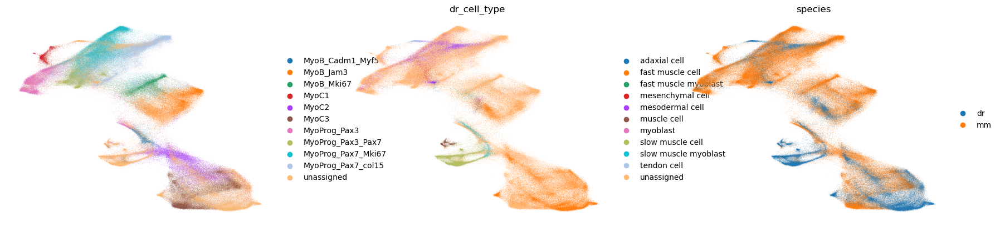

In [ ]:
sc.pl.umap(samap.adata, color=['mm_cell_type', 'dr_cell_type', 'species'], frameon=False, title='') #, save='umap1.svg'

### From cell-type alignment to candidate conserved programs

Cell-type mapping scores were calculated after construction of the joint SAMap manifold.

The mapping matrix provides a quantitative representation of the correspondence between mouse and zebrafish annotated cell populations. A Sankey representation is used to visualize the strongest relationships between cell types/states.

In addition, SAMap's GenePairFinder was used to identify gene pairs contributing to individual cross-species cell-state/type relationships.

SAMap can highlight combinations of homologous genes whose expression patterns support conserved cellular programs despite evolutionary divergence. This is the purpose of SAMap analysis: cellular states do not necessarily rely exclusively on strict one-to-one orthologues. 

These gene pairs therefore provide candidate molecular explanations for the cell-state relationships observed in the mapping matrix. 

In [17]:
sm.samap.adata.write(SAMAP_H5AD_PATH)

In [18]:
save_samap(sm, str(SAMAP_OBJECT_PATH))

INFO: Saved SAMAP object to /home/sabrina/Documents/BioHack26/samap_3species/data/samap/SamapObject_mm_dr_annot.pkl


In [ ]:
samap_mm_dr = sc.read_h5ad(SAMAP_H5AD_PATH)

In [ ]:
samap_mm_dr.var_names

Index(['mm_4933401J01Rik', 'mm_Gm26206', 'mm_Xkr4', 'mm_Gm18956', 'mm_Gm37180',
       'mm_Gm37363', 'mm_Gm37686', 'mm_Gm1992', 'mm_Gm37329', 'mm_Gm7341',
       ...
       'dr_CR926130.2', 'dr_BX511073.1', 'dr_BX908750.2', 'dr_BX323593.1',
       'dr_CABZ01085061.1', 'dr_BX537296.5', 'dr_CABZ01064670.1',
       'dr_CU207269.4', 'dr_CR385041.2', 'dr_CR388164.3'],
      dtype='str', length=77556)

In [ ]:
samap_mm_dr

AnnData object with n_obs × n_vars = 406874 × 77556
    obs: 'mm_donor_id', 'mm_development_stage_ontology_term_id', 'mm_sex_ontology_term_id', 'mm_self_reported_ethnicity_ontology_term_id', 'mm_disease_ontology_term_id', 'mm_tissue_ontology_term_id', 'mm_cell_type_ontology_term_id', 'mm_assay_ontology_term_id', 'mm_suspension_type', 'mm_author_experimental_id', 'mm_author_day', 'mm_author_somite_count', 'mm_author_major_cell_cluster', 'mm_author_cell_type', 'mm_tissue_type', 'mm_cell_type', 'mm_assay', 'mm_disease', 'mm_sex', 'mm_tissue', 'mm_self_reported_ethnicity', 'mm_development_stage', 'mm_leiden_clusters', 'dr_projection_group', 'dr_cell_type_long', 'dr_cell_type_broad', 'dr_embryo_ID', 'dr_perturbation', 'dr_target', 'dr_type', 'dr_strain', 'dr_expt', 'dr_cross_batch', 'dr_collection_batch', 'dr_cell_type_ontology_term_id', 'dr_donor_id', 'dr_tissue_type', 'dr_cell_line_ontology_term_id', 'dr_perturbation_strategy', 'dr_perturbation_role', 'dr_perturbation_target_gene_id', 'dr

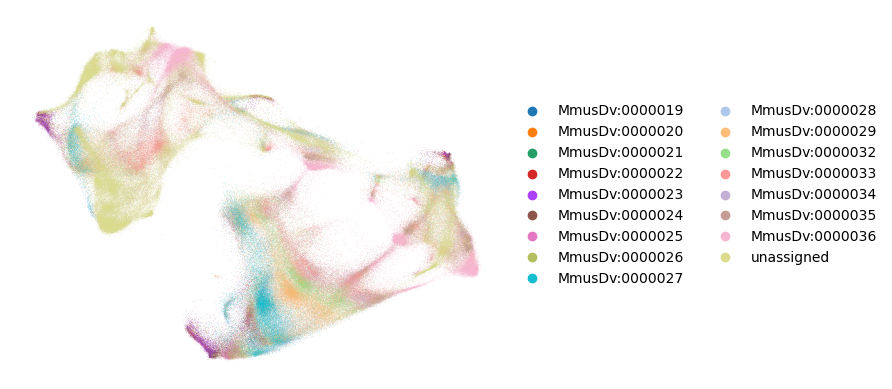

In [ ]:
sc.pl.umap(samap_mm_dr, color='mm_development_stage_ontology_term_id', frameon=False, title='') #, save='umap1.svg'